# L1S11 / L1S12: reproducible PZT feature feasibility

**Assessment:** simple regression is worth a limited trial. All 29 published checkpoints remain in the matched three-path subset, but there are only two independent coupons. RMS has strong within-specimen associations; waveform correlation is repeat-sensitive. The L1S12 jump is retained and the physical sample rate remains unresolved.

No interpolation, trained model, target-ranked path selection, or modification of original files. See `ASSESSMENT.md` for full evidence and limits.

## Context and methods

Use traction-free recordings and the pristine zero-load baseline. Survey acquisition metadata before selecting paths. Require full labelled-cycle coverage and exact baseline compatibility, select the frequency with most eligible paths, then the first three actuator/sensor pairs numerically. Numerical target values play no part in selection.

**Assumptions:** each specimen has its own initial calibration waveform available; same-path matching settings and sample grids support sample-domain comparison. We do not assume the exported clock is physically correct. Missing targets stay missing.

In [1]:
from pathlib import Path
import sys, io, contextlib, json
import pandas as pd
from IPython.display import display, Image
out = Path.cwd() if (Path.cwd()/'run_feasibility.py').exists() else Path.cwd()/'pzt_feasibility'
sys.path.insert(0, str(out.resolve()))
import run_feasibility as pzt


## 1. Survey and select by acquisition metadata

The inventory reads all 254 PZT files on first run. Later runs verify every source SHA-256 before reusing it. All downstream signals are read again from the original MAT files. Paths are keyed by actuator, sensor and frequency, never by array index.

In [2]:
inventory = pzt.survey()
plan = pzt.choose_paths(inventory)
display(pd.DataFrame(plan['paths']))
print('Eligible settings by nominal frequency:', plan['eligible_per_frequency'])
print('Selection rule:', plan['rule'])


,actuator,sensor,frequency_raw,gain_raw,amplitude_raw,sampling_rate,sensor_n,actuator_n
0,1,10,450,20,25,1200000,2000,2000
1,2,8,450,20,35,1200000,2000,2000
2,2,11,450,20,15,1200000,2000,2000


Eligible settings by nominal frequency: {'300': 1, '350': 2, '400': 3, '450': 19}
Selection rule: Require all labelled cycles and pristine references in both coupons with exact settings; choose frequency with most eligible paths (tie: lower frequency); take first three actuator/sensor pairs in numeric order.


## 2. Extract signals, screen quality and calculate features

Each whole trace is centered by its own mean. RMS = sqrt(mean(x²)); the conditional rectangle-rule integral = sum(x²)/exported_fs; zero-lag correlation = dot(x,r)/(norm(x) norm(r)). The primary amplitude features divide by the same-path pristine reference. No filtering, time alignment or target-selected window is used.

Clipping checks are heuristics because hardware rails are unknown. See `selection_plan.json` for fixed thresholds.

In [3]:
with contextlib.redirect_stdout(io.StringIO()):
    features = pzt.extract(plan)
    features = pzt.enrich_and_summarize(features, inventory)
    pzt.sampling_check()
display(pd.read_csv(out/'usable_coverage.csv'))
qc = pd.read_csv(out/'signal_qc.csv')
display(qc.groupby('channel').agg(traces=('file','size'),nonfinite_samples=('nonfinite','sum'),flat_traces=('flat','sum'),clipping_suspicions=('clipping_suspect','sum')))
print('Lengths:', sorted(qc.n.unique()))
print('Setting mismatches:', int((~features.settings_match).sum()))


C:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


,specimen,labelled_recordings,labelled_checkpoints,feature_rows
0,L1_S11_F,32,15,96
1,L1_S12_F,26,14,78


,traces,nonfinite_samples,flat_traces,clipping_suspicions
channel,,,,
actuator,189,0,0,0
sensor,189,0,0,0


Lengths: [np.int64(2000)]
Setting mismatches: 0


## 3. Verify sampling units and reference compatibility

Nominal excitation uses kHz according to the README; the export hard-codes 1.2 MHz. At nominal 450 kHz the pristine excitation FFT peak is 46.2–46.8 kHz if interpreted using that rate. Across all seven nominal frequencies there is a similar roughly tenfold discrepancy. A near-12-MHz clock is an inference, not an adopted correction. Absolute time integrals remain conditional; reference ratios cancel the shared clock scale. Signal amplitudes are treated as arbitrary exported units.

References are each specimen's pristine `_0_0.mat`, not averages of later cycle-zero static-loading records. Their path, settings, length and rate match.

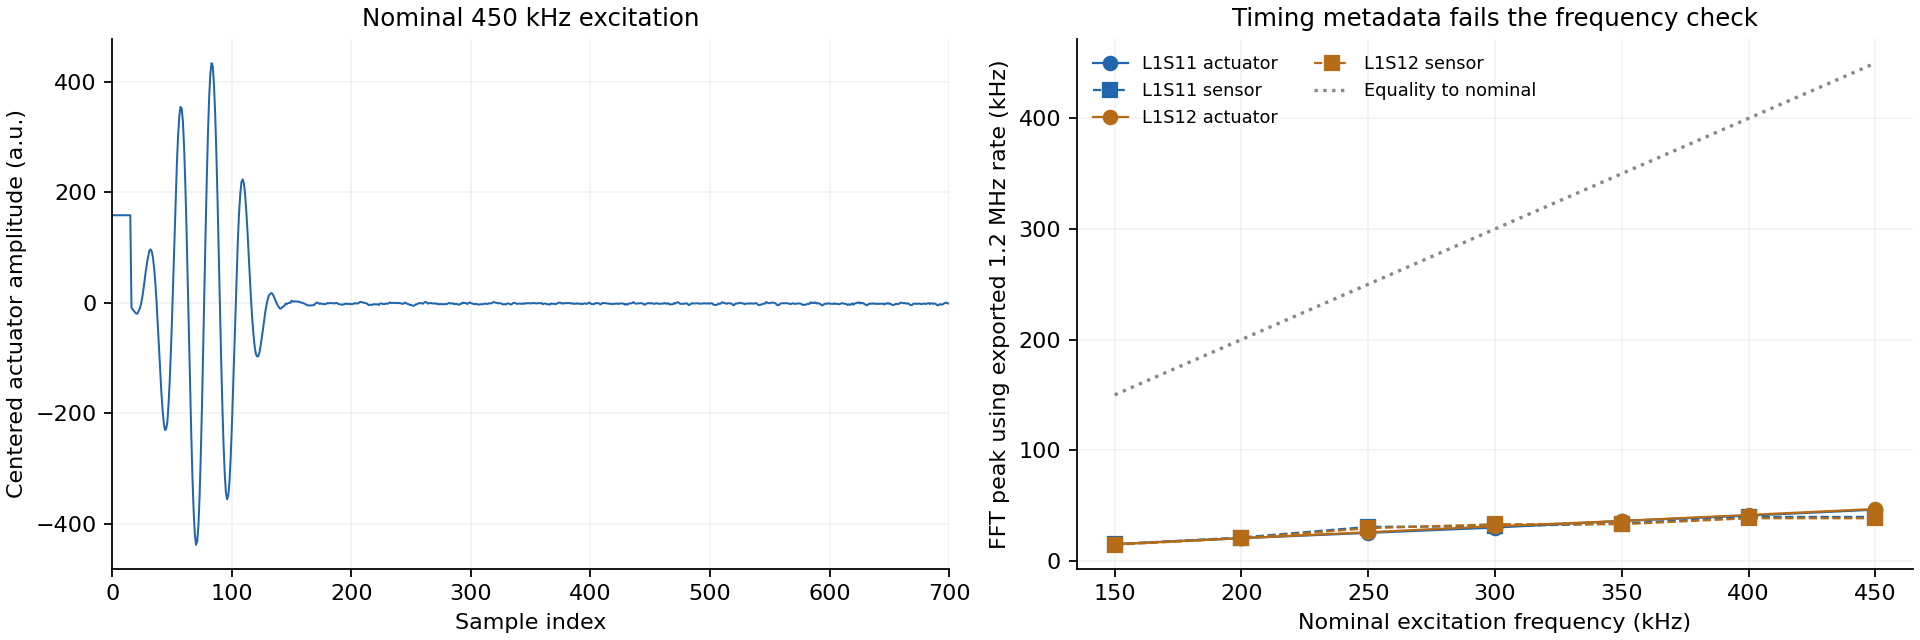

In [4]:
pzt.plots(features, plan)
display(Image(filename=str(out/'sampling_check.png'), width=1000))


## 4. Features by specimen, cycle and published index

All repetitions remain individual points. Marker shape identifies repeat number and CSV filenames retain exact identities. Open points have a measured PZT feature but no published target; they appear only on the cycle axis. No curves are fitted or interpolated. Amplitude and correlation scales match across specimen figures.

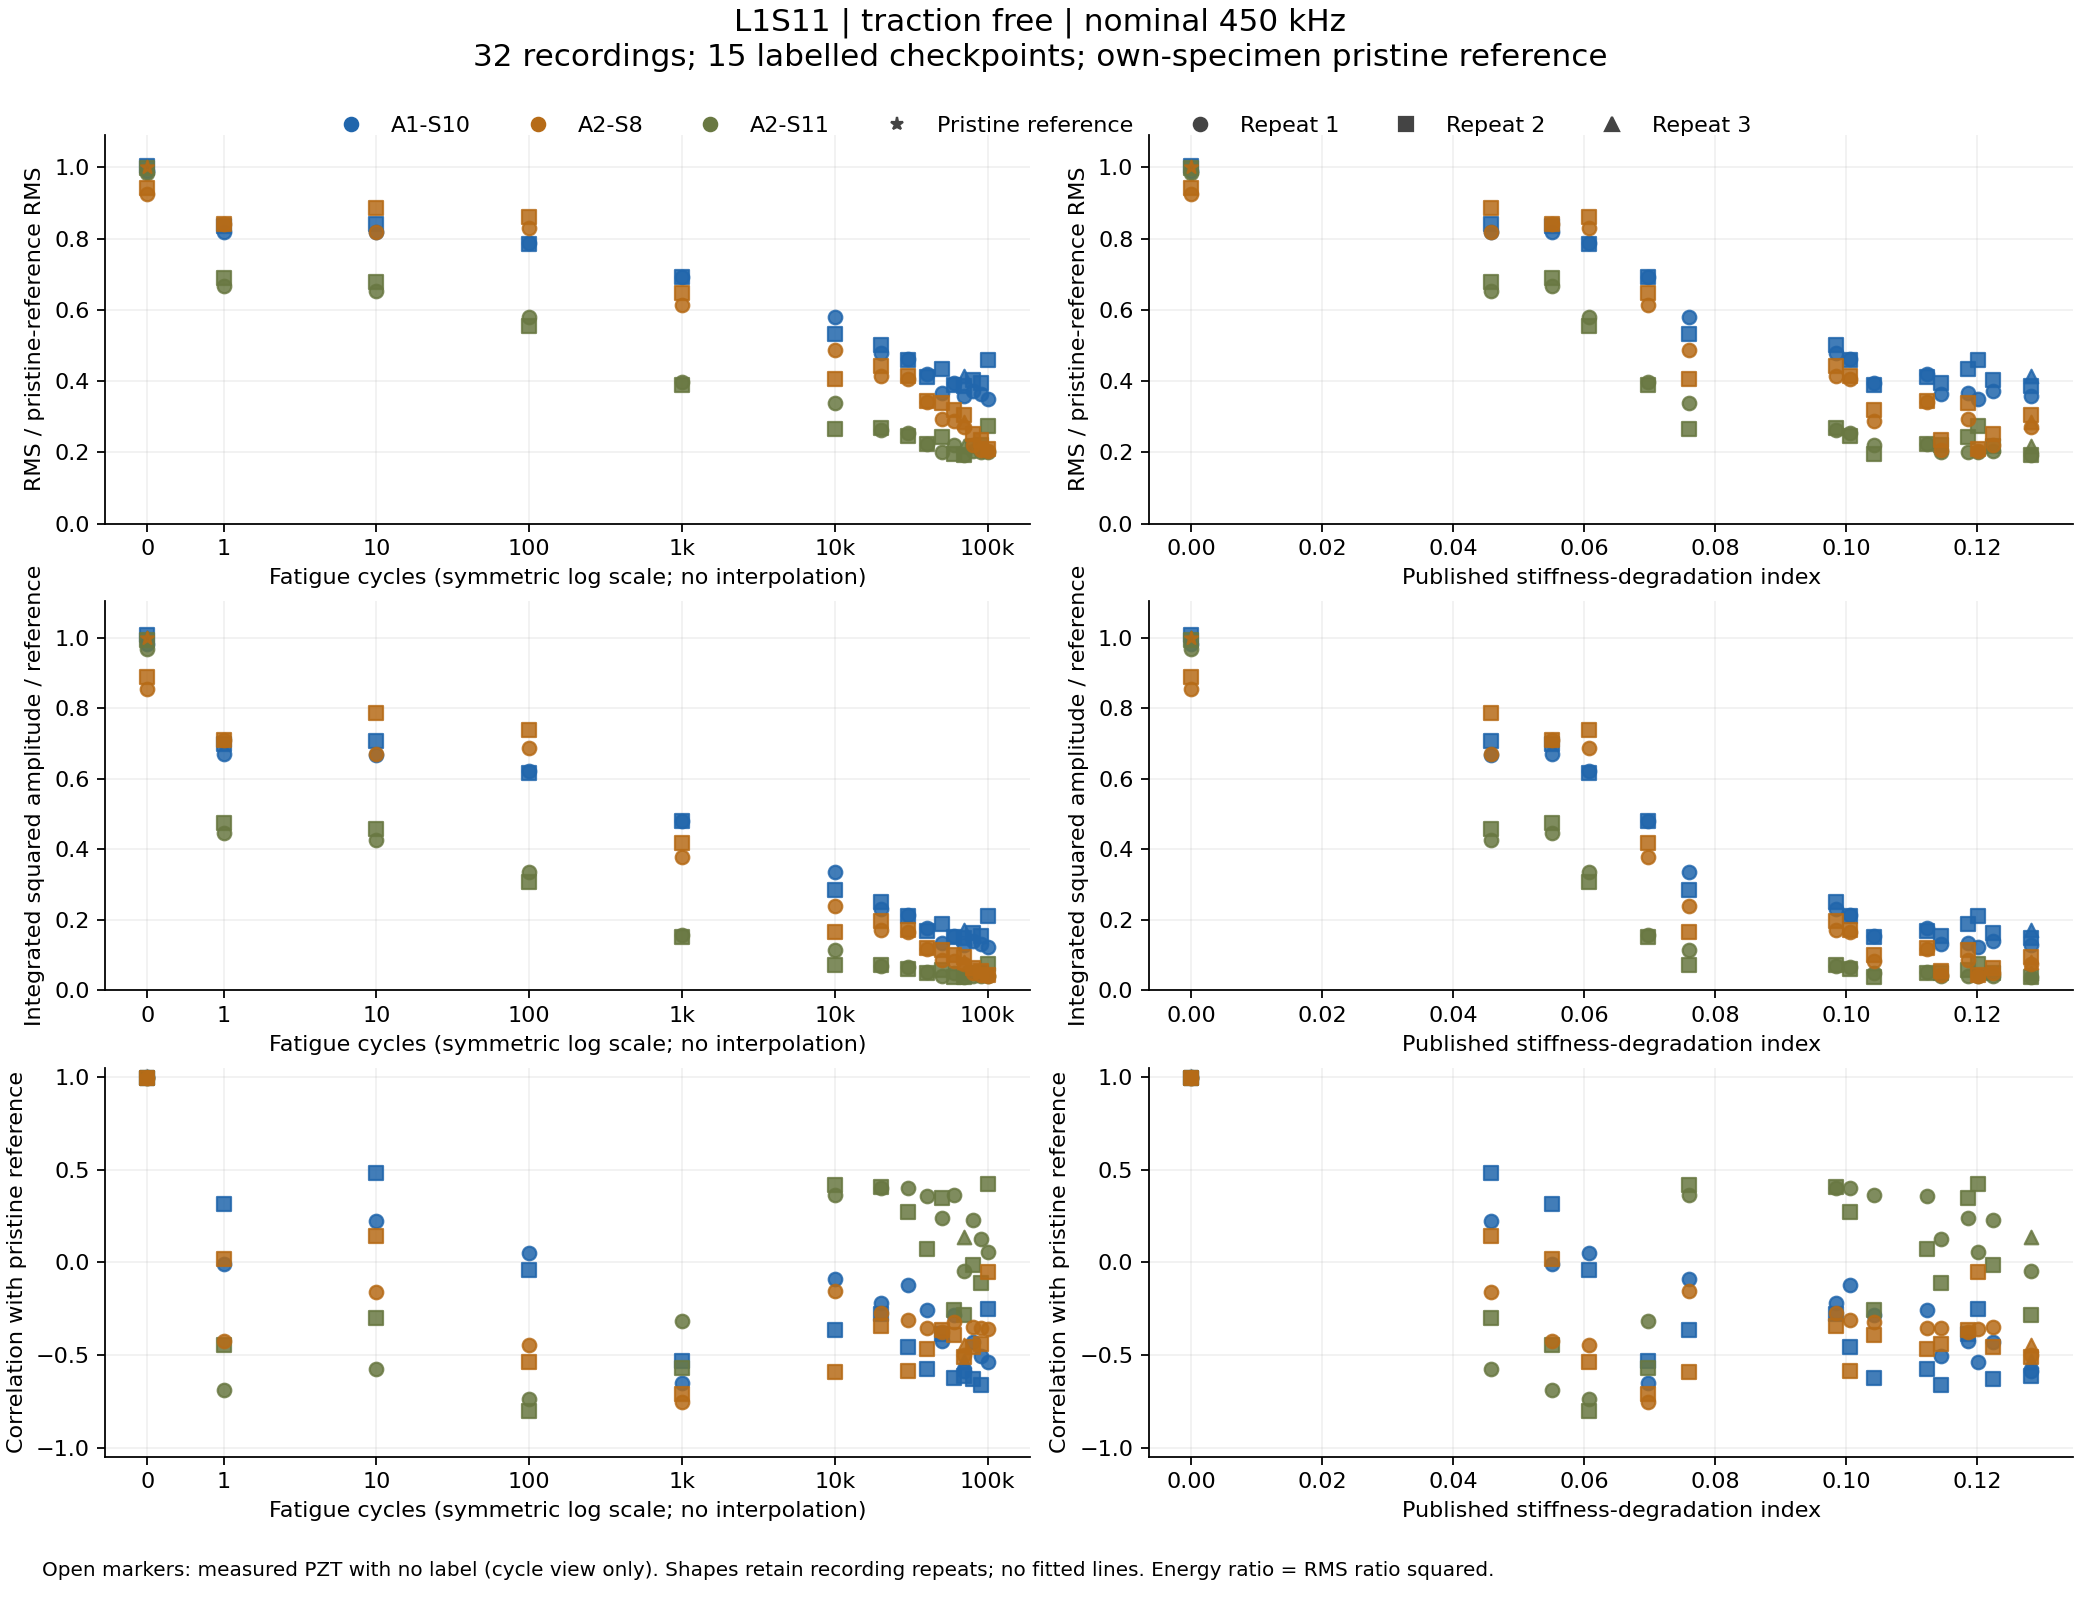

In [5]:
display(Image(filename=str(out/'L1S11_features.png'), width=1000))


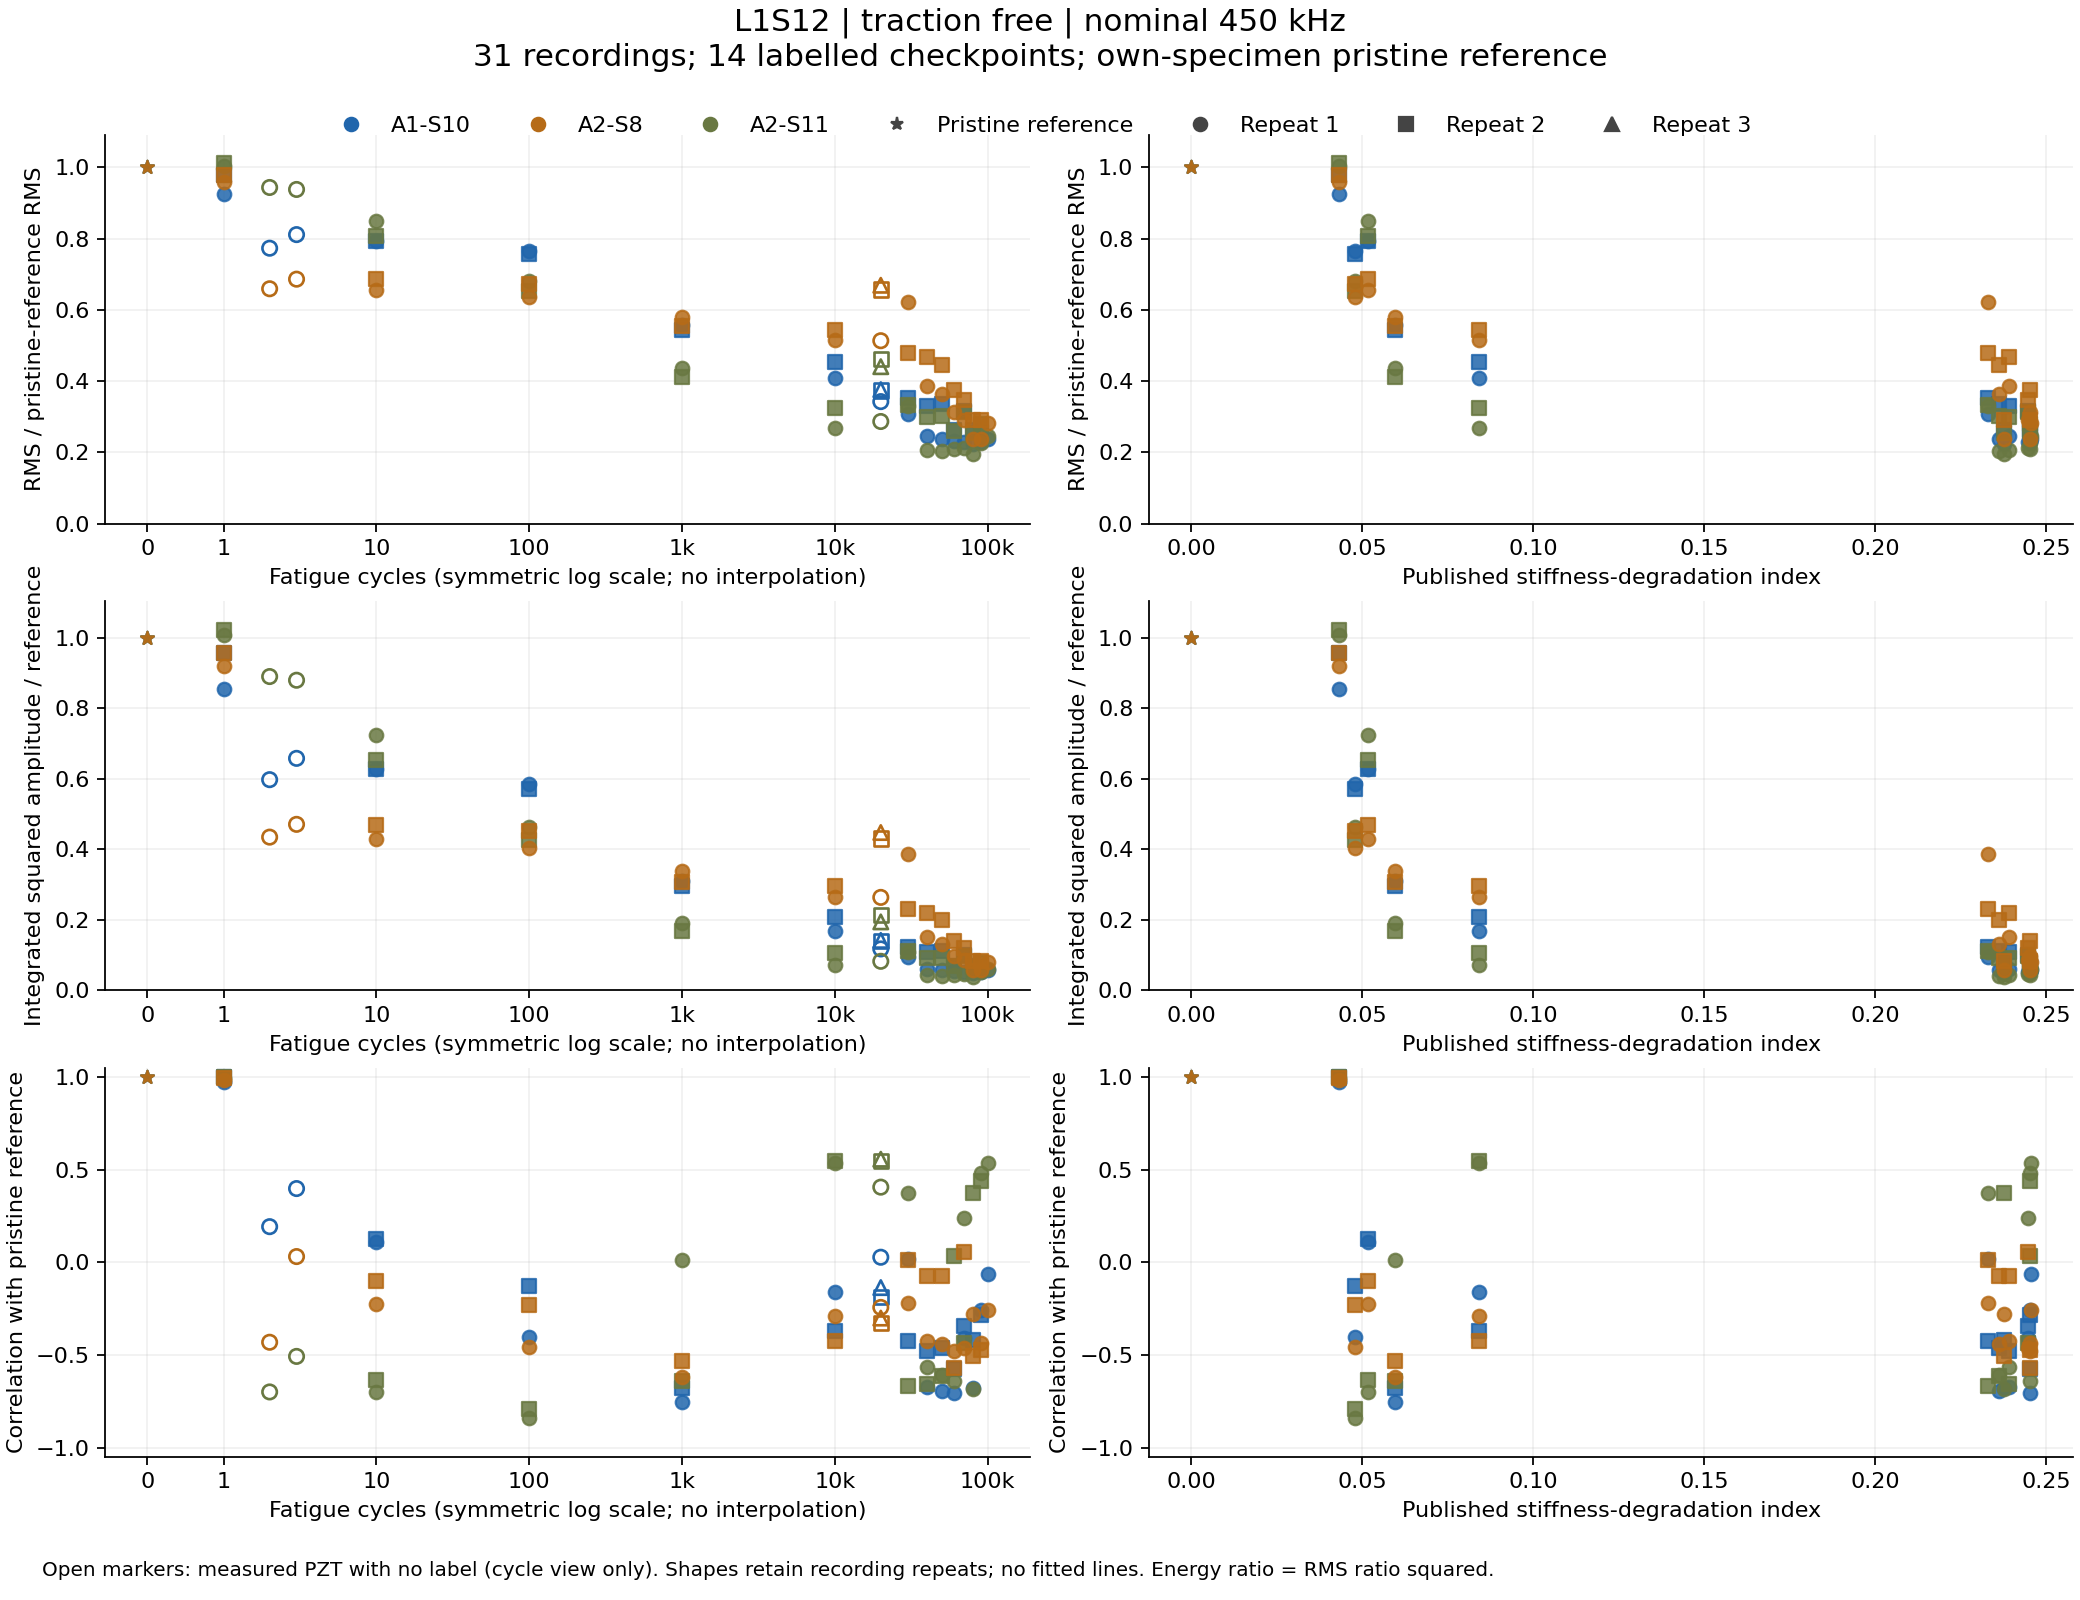

In [6]:
display(Image(filename=str(out/'L1S12_features.png'), width=1000))


RMS decreases within each coupon. Integrated squared-amplitude ratio is exactly RMS ratio squared per recording, so these are redundant predictors. Signed zero-lag correlation is less stable and must not be interpreted as a monotonic damage measure.

## 5. L1S12 10k–30k interval: facts and hypotheses

The index rises from 0.084112497 to 0.233175942; 20k is unlabelled. Logbook rows 53–71 document a September–November gap, temporary absence of strain gauges, later rosette recordings and observed vertical delamination growth. All stored gain, drive-amplitude, sample-rate and length fields remain unchanged across all 252 paths in the seven traction-free records.

At 30k, the operator notes a signal shift and suggests dye or temperature. Those causes remain hypotheses. Damage growth, gauge/calibration changes and environmental effects cannot be separated here. No automatic deletion or smoothing is performed.

,file,paths_checked,changed_settings_paths
0,L1S12_10000_3_1.mat,252,0
1,L1S12_10000_3_2.mat,252,0
2,L1S12_20000_3_1.mat,252,0
3,L1S12_20000_3_2.mat,252,0
4,L1S12_20000_3_3.mat,252,0
5,L1S12_30000_3_1.mat,252,0
6,L1S12_30000_3_2.mat,252,0


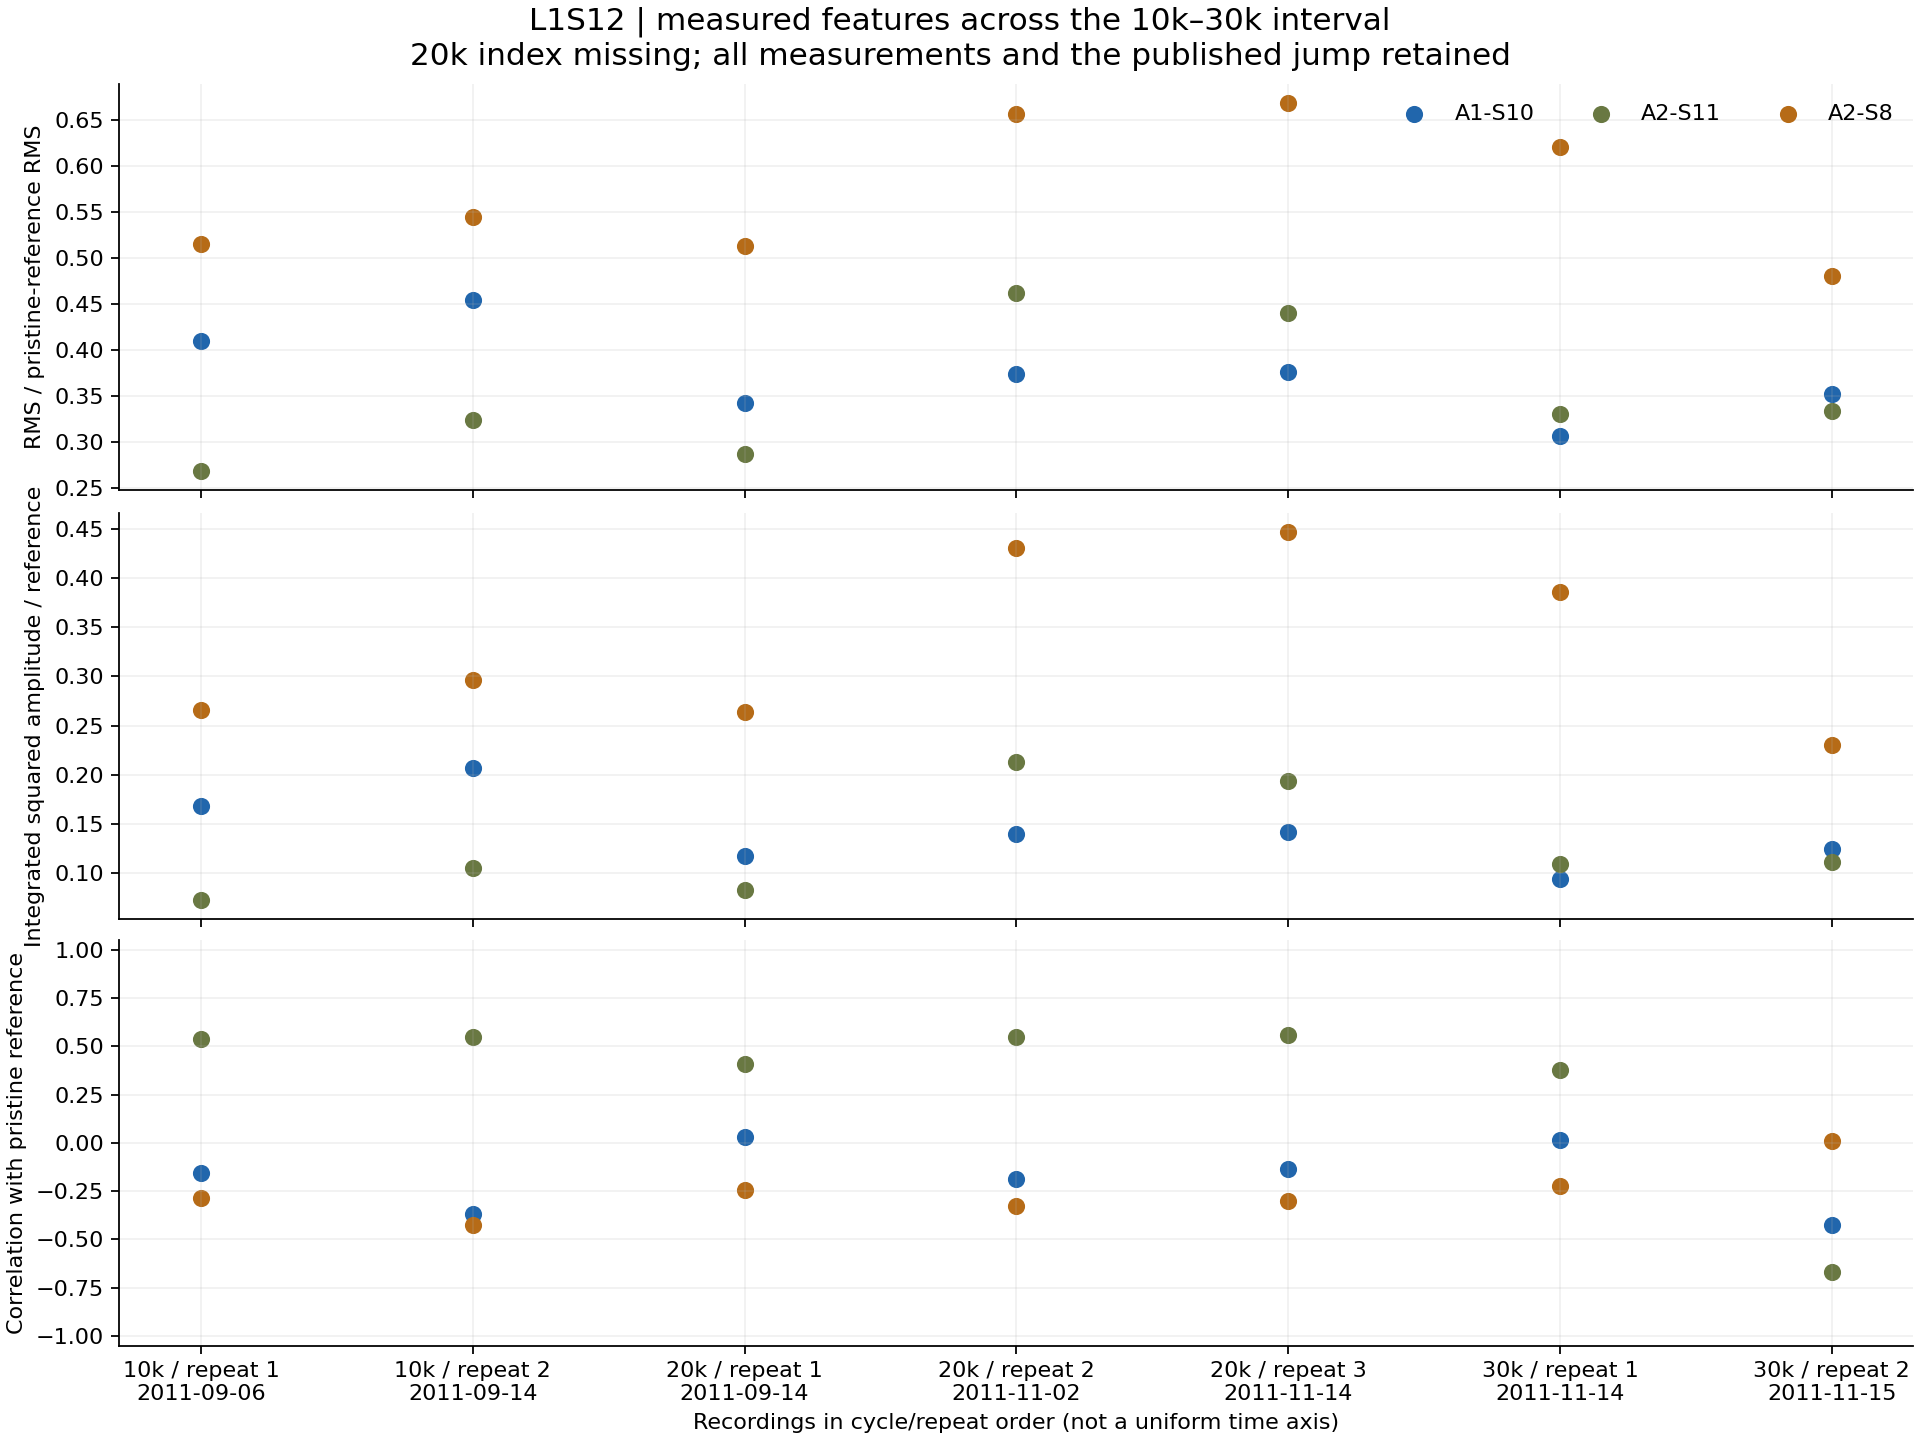

In [7]:
display(pd.read_csv(out/'L1S12_jump_setting_changes.csv')[['file','paths_checked','changed_settings_paths']])
display(Image(filename=str(out/'L1S12_jump.png'), width=1000))


At A2→S11, 30k-repeat reference correlations are +0.37745 and -0.66720 while RMS ratios are 0.33068 and 0.33338. A shared stiffness target therefore coexists with markedly different phase-sensitive similarity. The unlabelled 20k repeats show variability without an assigned target.

## 6. Waveform inspection and descriptive associations

The waveforms below compare matched pristine and 100k acquisitions in sample coordinates. Associations use one median per checkpoint/path, not thousands of path samples as independent observations. These statistics are descriptive; they were calculated only after selection and never used to choose paths.

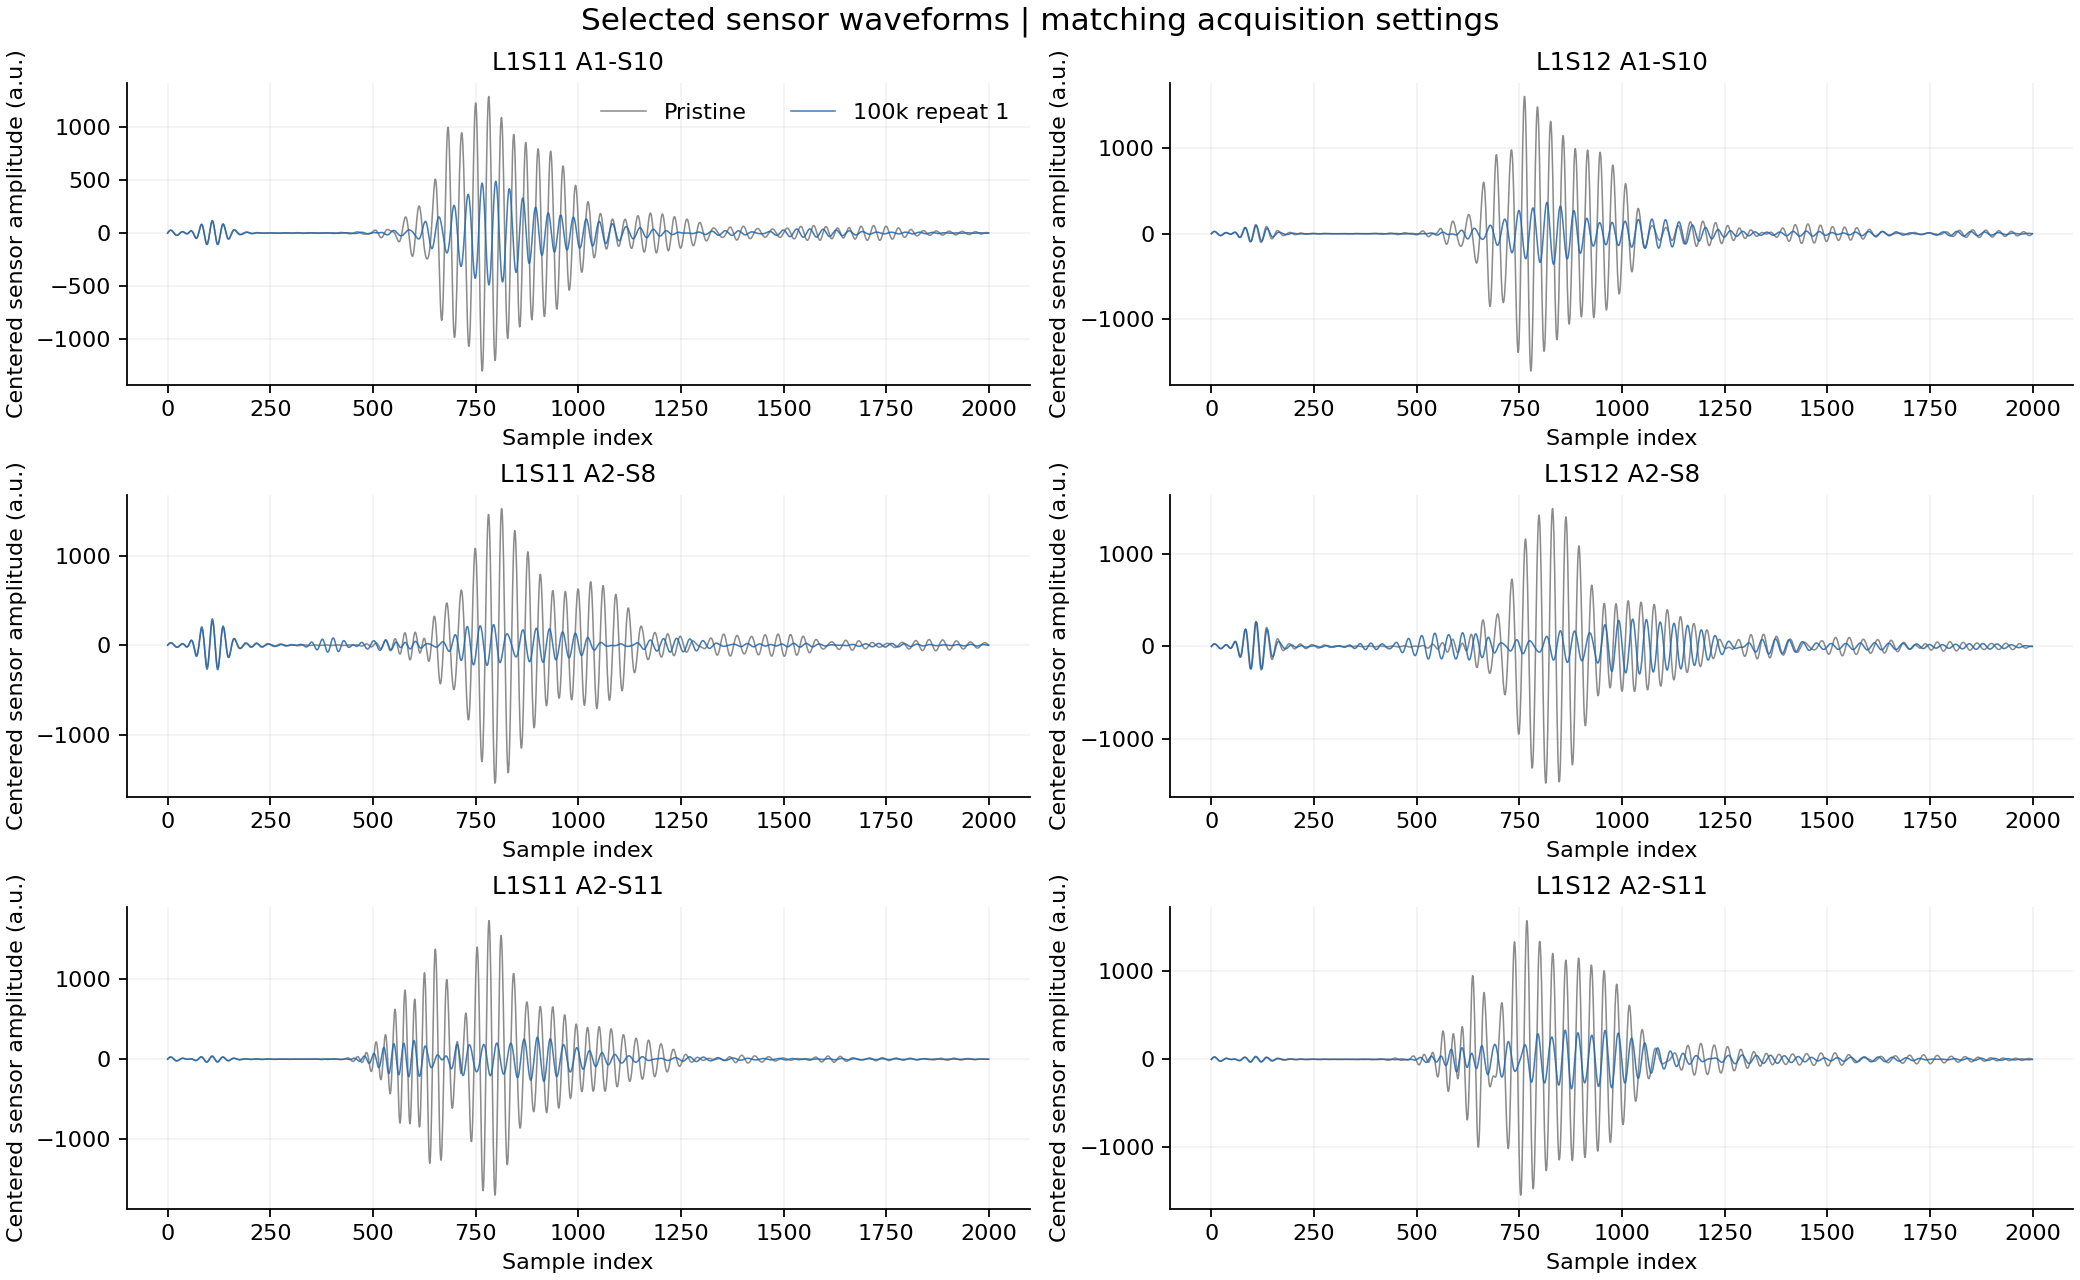

,specimen,path,feature,n_checkpoints,spearman_index,spearman_cycles
0,L1_S11_F,A1-S10,rms_ratio,15,-0.932,-0.939
2,L1_S11_F,A1-S10,reference_correlation,15,-0.732,-0.711
3,L1_S11_F,A2-S11,rms_ratio,15,-0.918,-0.893
5,L1_S11_F,A2-S11,reference_correlation,15,0.100,0.100
6,L1_S11_F,A2-S8,rms_ratio,15,-0.939,-0.989
8,L1_S11_F,A2-S8,reference_correlation,15,-0.389,-0.279
9,L1_S12_F,A1-S10,rms_ratio,14,-0.960,-0.996
11,L1_S12_F,A1-S10,reference_correlation,14,-0.451,-0.442
12,L1_S12_F,A2-S11,rms_ratio,14,-0.859,-0.903
14,L1_S12_F,A2-S11,reference_correlation,14,-0.007,0.007


In [8]:
display(Image(filename=str(out/'waveform_check.png'), width=1000))
assoc = pd.read_csv(out/'descriptive_associations.csv')
display(assoc[assoc.feature.ne('energy_ratio')].round(3))


## 7. Reproducibility and preservation checks

Checks cover label coverage, exact reference identities, amplitude-feature algebra, target missingness, zero recorded load, correlation bounds and source preservation. SHA-256 compares every surveyed PZT file; the earlier inventory also checks all 2,571 original file sizes/timestamps. Package versions are saved in `environment.json`.

In [9]:
pzt.verify(features)
display(pd.Series(json.loads((out/'environment.json').read_text()), name='Version'))


Verification passed: {"pzt_sha256_files_checked": 254, "pzt_hash_changes": [], "original_metadata_files_checked": 2571, "original_metadata_changes": [], "feature_identity_checks": "passed", "missing_labels_preserved": true, "models_trained": 0}


python        3.13.3
numpy          2.3.0
pandas         2.2.3
scipy         1.17.1
matplotlib    3.10.6
openpyxl       3.1.5
Name: Version, dtype: object

## Takeaways

- 15 L1S11 and 14 L1S12 labelled checkpoints remain; 58 labelled recordings are repeated views, not 58 independent specimens.
- No selected trace failed the basic screens, but physical timing calibration and absolute amplitude calibration are unresolved.
- Try a predeclared low-dimensional regularized regression with RMS ratios **or** energy ratios, compared with a cycle-only baseline. Treat correlation as a separate sensitivity analysis.
- Hold out an entire coupon and report both transfer directions; never select the best path from held-out target performance. For forecasting, add forward-time splits.
- Preserve the L1S12 jump, the missing 20k label and identifiable repeats. Results cannot establish broad generalization from two coupons.

Controlling sources: local Layup1 README, Technical Report export code, the two logbooks, original MAT fields and the existing audit. No new labels were manufactured.